# TASK 5 · Sales Prediction Using Python

## Project Objective
Build regression models to predict **Sales** from advertising expenditure across available media channels such as TV, Radio, and Newspaper.

**Dataset:** Uploaded CSV file — `Advertising Budget and Sales.csv`  
**Tech Stack:** Python, pandas, NumPy, scikit-learn, matplotlib, seaborn, Jupyter Notebook

### Important approach
This notebook uses the **uploaded CSV as the primary and only dataset source**. It inspects the actual columns before selecting the target and advertising features, removes only an unnecessary index-like column, performs EDA, trains Linear Regression and Random Forest Regression models, evaluates them with MAE/RMSE/R², and performs residual and feature-importance analysis.


## 1. Import Libraries

We import the libraries needed for data handling, visualization, regression, and evaluation. A fixed random state is used where applicable so the train/test split and Random Forest results are reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(RANDOM_STATE)


## 2. Load Dataset

The uploaded CSV is loaded directly from the notebook's working directory. In this environment the file is named `Advertising Budget and Sales.csv`.

In [2]:
from pathlib import Path

DATA_PATH = Path("Advertising Budget and Sales.csv")

# If the notebook is run from another directory, adjust DATA_PATH to the uploaded CSV location.
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place the uploaded CSV in the notebook's working directory."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")
df.head()


Dataset loaded successfully.
Shape: (200, 5)


,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


## 3. Data Inspection

We inspect the first and last rows, shape, column names, data types, missing values, duplicate rows, and descriptive statistics. This helps identify data-quality issues before modeling.

In [3]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe().T)


First 5 rows:


,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9



Last 5 rows:


,Unnamed: 0,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($),Sales ($)
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5
199,200,232.1,8.6,8.7,13.4



Dataset shape: (200, 5)

Column names:
['Unnamed: 0', 'TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)', 'Sales ($)']

Data types:


,dtype
Unnamed: 0,int64
TV Ad Budget ($),float64
Radio Ad Budget ($),float64
Newspaper Ad Budget ($),float64
Sales ($),float64



Missing values:


,missing_values
Unnamed: 0,0
TV Ad Budget ($),0
Radio Ad Budget ($),0
Newspaper Ad Budget ($),0
Sales ($),0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,200.0,100.5000,57.879185,1.0,50.750,100.50,150.250,200.0
TV Ad Budget ($),200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio Ad Budget ($),200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper Ad Budget ($),200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales ($),200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


## 4. Data Cleaning and Automatic Column Identification

The uploaded file contains an index-like column named `Unnamed: 0`. It contains sequential row identifiers rather than a modeling feature, so it is removed from the working copy.

The target is identified by finding a column whose normalized name contains `sales`. Advertising features are then identified from column names containing advertising/media keywords such as `TV`, `Radio`, or `Newspaper`. This makes the notebook adaptable to small naming variations without assuming exact column names.

An IQR-based check is also used to flag unusually high/low numeric observations. An outlier flag is **not** automatically deleted because an unusual observation is not necessarily an error.

In [4]:
# Work on a copy so the original loaded data remains unchanged.
df_model = df.copy()

# Remove obvious index columns only when they look like row identifiers.
index_like_cols = []
for col in df_model.columns:
    normalized = str(col).strip().lower().replace(" ", "").replace("_", "")
    if normalized.startswith("unnamed:") or normalized in {"index", "id"}:
        index_like_cols.append(col)

if index_like_cols:
    print("Removing index-like column(s):", index_like_cols)
    df_model = df_model.drop(columns=index_like_cols)

# Normalize names only for matching; keep the original column names in the data.
def normalize_name(name):
    return (
        str(name).strip().lower()
        .replace("_", " ")
        .replace("-", " ")
    )

sales_candidates = [
    col for col in df_model.columns
    if "sales" in normalize_name(col)
]

if not sales_candidates:
    raise ValueError("Could not automatically identify a Sales target column.")

target_column = sales_candidates[0]

media_keywords = ["tv", "radio", "newspaper", "advert", "advertising", "ad budget", "media"]
feature_candidates = [
    col for col in df_model.columns
    if col != target_column and any(k in normalize_name(col) for k in media_keywords)
]

# Fall back to numeric non-target columns if the naming convention is unusual.
if not feature_candidates:
    feature_candidates = [
        col for col in df_model.select_dtypes(include=np.number).columns
        if col != target_column
    ]

if not feature_candidates:
    raise ValueError("Could not identify advertising/input features.")

# Keep numeric predictors and remove rows with missing values only if any exist.
feature_candidates = [
    col for col in feature_candidates
    if pd.api.types.is_numeric_dtype(df_model[col])
]

print("Identified target:", target_column)
print("Identified advertising/input features:", feature_candidates)

# Missing-value check before modeling.
missing_total = df_model[[target_column] + feature_candidates].isna().sum().sum()
if missing_total > 0:
    print(f"Missing values detected: {missing_total}. Rows with missing model fields will be removed.")
    df_model = df_model.dropna(subset=[target_column] + feature_candidates).copy()
else:
    print("No missing values in the selected modeling columns.")

# IQR-based unusual-value check.
outlier_report = []
for col in feature_candidates + [target_column]:
    q1 = df_model[col].quantile(0.25)
    q3 = df_model[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df_model[col] < lower) | (df_model[col] > upper)).sum())
    outlier_report.append([col, lower, upper, count])

outlier_report = pd.DataFrame(
    outlier_report,
    columns=["Column", "IQR Lower Bound", "IQR Upper Bound", "Flagged Values"]
)

display(outlier_report)
print("\nModeling dataset shape:", df_model.shape)


Removing index-like column(s): ['Unnamed: 0']
Identified target: Sales ($)
Identified advertising/input features: ['TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)']
No missing values in the selected modeling columns.


,Column,IQR Lower Bound,IQR Upper Bound,Flagged Values
0,TV Ad Budget ($),-142.3000,435.5000,0
1,Radio Ad Budget ($),-29.8500,76.3500,0
2,Newspaper Ad Budget ($),-35.7750,93.6250,2
3,Sales ($),-0.1625,27.9375,0



Modeling dataset shape: (200, 4)


## 5. Exploratory Data Analysis

### Pairplot

A pairplot shows pairwise relationships among all selected numeric advertising variables and Sales. It is useful for quickly seeing direction, strength, clustering, and possible nonlinear patterns.

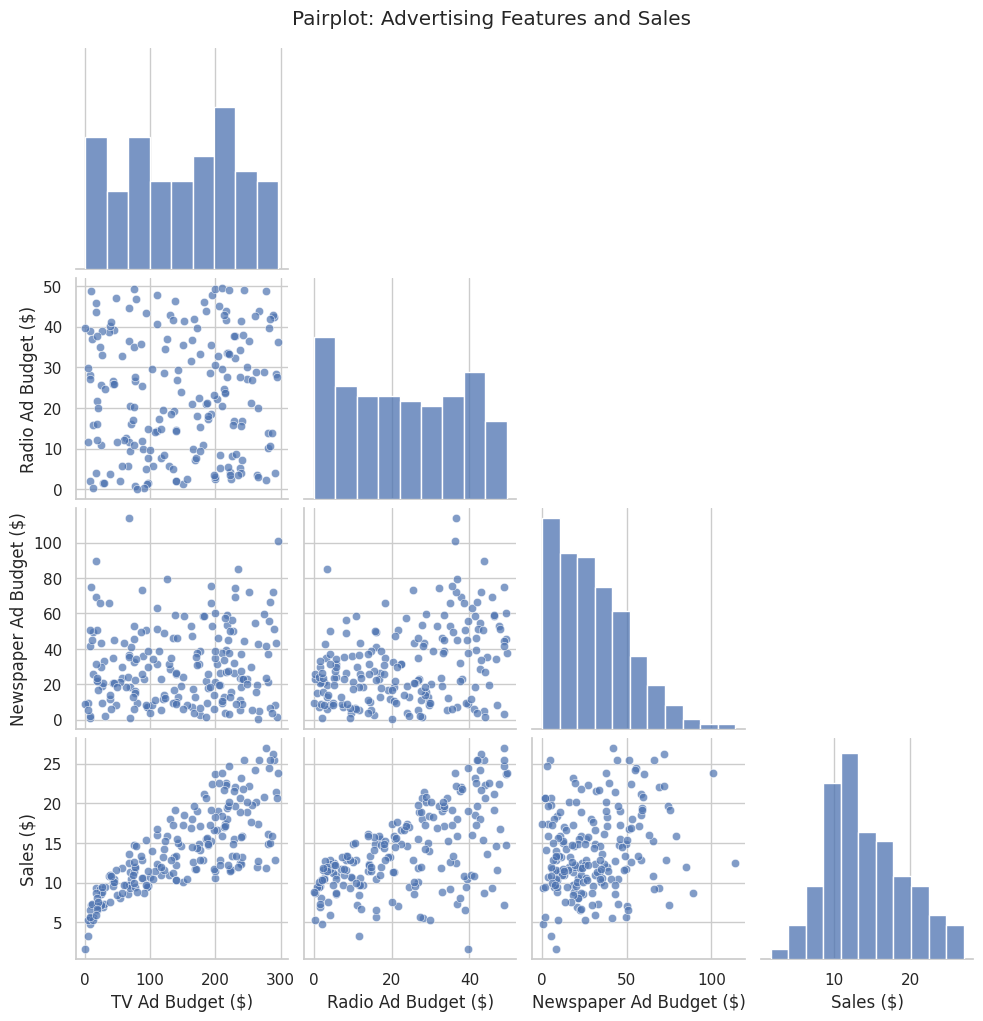

In [5]:
eda_columns = feature_candidates + [target_column]

# Explicitly provide a palette so this pairplot works across common seaborn/matplotlib versions.
sns.set_palette("deep")
sns.pairplot(
    df_model[eda_columns],
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.7},
    diag_kws={"color": "C0"}
)
plt.suptitle("Pairplot: Advertising Features and Sales", y=1.02)
plt.show()


### Individual Scatter Plots

Each scatter plot compares one advertising channel with Sales. An upward pattern indicates a positive association, but these plots alone do **not** prove that increasing advertising causes higher sales.

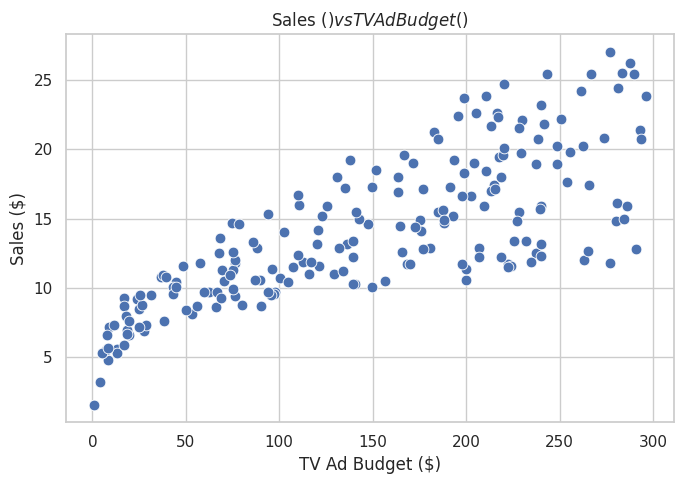

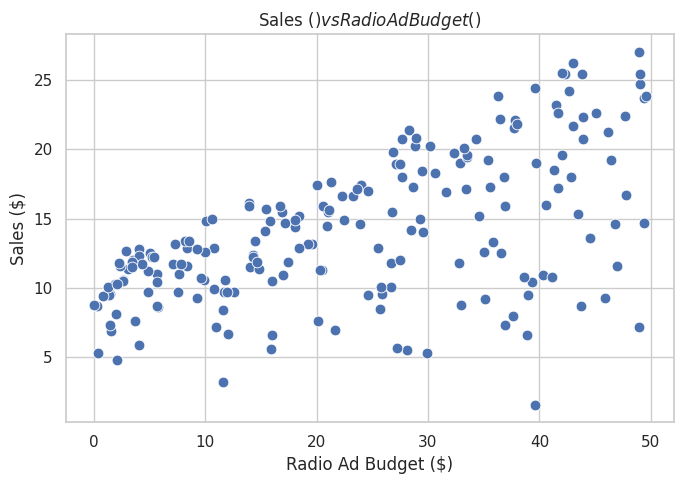

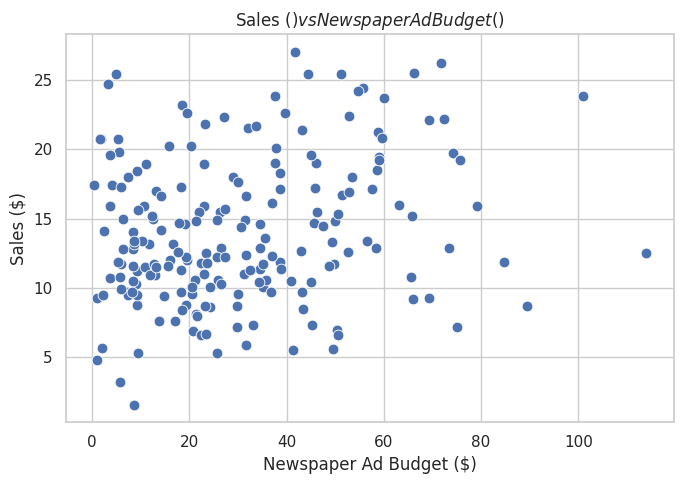

In [6]:
for feature in feature_candidates:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df_model, x=feature, y=target_column, s=60)
    plt.title(f"{target_column} vs {feature}")
    plt.xlabel(feature)
    plt.ylabel(target_column)
    plt.tight_layout()
    plt.show()


### Correlation Matrix

Correlation measures the strength and direction of a linear relationship. Values near +1 indicate strong positive linear association, values near -1 indicate strong negative association, and values near 0 indicate weak linear association.

Correlation does not establish causation. Correlations among predictors are also useful for checking possible multicollinearity.

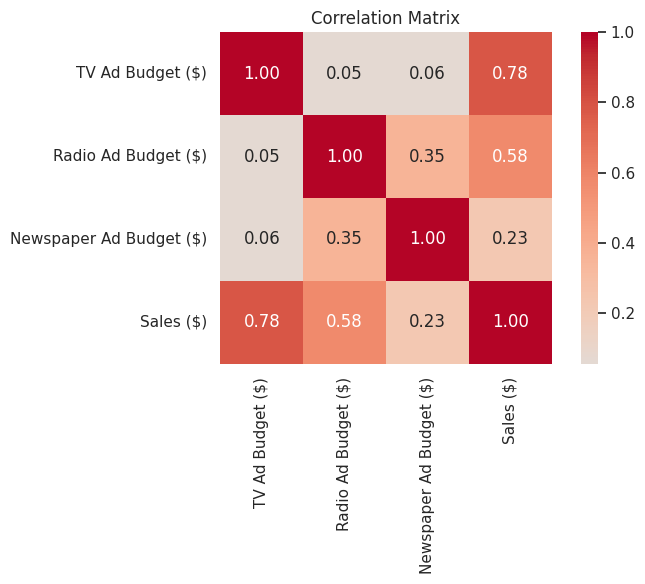

Advertising variables ranked by absolute correlation with Sales:


,Correlation with Sales
TV Ad Budget ($),0.782224
Radio Ad Budget ($),0.576223
Newspaper Ad Budget ($),0.228299


Predictor-to-predictor correlations (useful for checking multicollinearity):


,TV Ad Budget ($),Radio Ad Budget ($),Newspaper Ad Budget ($)
TV Ad Budget ($),1.000000,0.054809,0.056648
Radio Ad Budget ($),0.054809,1.000000,0.354104
Newspaper Ad Budget ($),0.056648,0.354104,1.000000


In [7]:
corr_matrix = df_model[eda_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

sales_correlations = corr_matrix[target_column].drop(target_column).sort_values(key=np.abs, ascending=False)
print("Advertising variables ranked by absolute correlation with Sales:")
display(sales_correlations.to_frame("Correlation with Sales"))

feature_corr = df_model[feature_candidates].corr()
print("Predictor-to-predictor correlations (useful for checking multicollinearity):")
display(feature_corr)


## 6. Feature/Target Selection

`X` contains the advertising input variables and `y` contains Sales. The target is kept separate because the model should learn to predict it from the inputs.

In [8]:
X = df_model[feature_candidates].copy()
y = df_model[target_column].copy()

print("Input features (X):", X.columns.tolist())
print("Target (y):", target_column)
print("X shape:", X.shape)
print("y shape:", y.shape)


Input features (X): ['TV Ad Budget ($)', 'Radio Ad Budget ($)', 'Newspaper Ad Budget ($)']
Target (y): Sales ($)
X shape: (200, 3)
y shape: (200,)


## 7. Train-Test Split

We reserve 20% of the data as an unseen test set. The model learns from the training set and is evaluated on the test set to estimate how well it generalizes to unseen observations.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("Training dimensions:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting dimensions:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


Training dimensions:
X_train: (160, 3)
y_train: (160,)

Testing dimensions:
X_test: (40, 3)
y_test: (40,)


## 8. Linear Regression

Linear Regression is used as the baseline model. It estimates Sales as a weighted sum of the advertising variables plus an intercept.

For a coefficient, the interpretation is: holding the other included predictors constant, a one-unit increase in that feature is associated with the corresponding change in predicted Sales.

In [10]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression intercept:", linear_model.intercept_)

linear_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

display(linear_coefficients)

print("First 10 Linear Regression predictions:")
display(pd.DataFrame({
    "Actual Sales": y_test.values[:10],
    "Predicted Sales": linear_predictions[:10]
}))


Linear Regression intercept: 2.9790673381226256


,Feature,Coefficient
0,TV Ad Budget ($),0.044730
1,Radio Ad Budget ($),0.189195
2,Newspaper Ad Budget ($),0.002761


First 10 Linear Regression predictions:


,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


## 9. Random Forest Regression

Random Forest combines many decision trees and averages their predictions. It can capture nonlinear relationships and interactions that a simple linear model may miss.

The number of trees and random state are fixed for reproducibility. The model is trained only on the training data.

In [11]:
random_forest = RandomForestRegressor(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)
rf_predictions = random_forest.predict(X_test)

print("Random Forest trained successfully.")
display(pd.DataFrame({
    "Actual Sales": y_test.values[:10],
    "Predicted Sales": rf_predictions[:10]
}))


Random Forest trained successfully.


,Actual Sales,Predicted Sales
0,16.9,17.732000
1,22.4,21.737667
2,21.4,20.868000
3,7.3,6.821333
4,24.7,23.099000
5,12.6,13.469333
6,22.3,22.498667
7,8.4,9.669667
8,11.5,11.845667
9,14.9,15.547000


## 10. Model Evaluation

We use three complementary metrics:

- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** square-rooted average squared error; lower is better and it penalizes larger errors more strongly.
- **R²:** proportion of target variance explained by the model on the test set; higher is generally better, but it should not be considered alone.

The model comparison should consider all three metrics together.

In [12]:
def evaluate_model(model_name, y_true, predictions):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R²": r2_score(y_true, predictions)
    }

evaluation_results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
])

display(evaluation_results)

# Select the model with the lower RMSE for the visualization/residual analysis.
selected_model_name = evaluation_results.sort_values("RMSE").iloc[0]["Model"]
if selected_model_name == "Linear Regression":
    selected_predictions = linear_predictions
    selected_model = linear_model
else:
    selected_predictions = rf_predictions
    selected_model = random_forest

print(f"Selected for detailed error analysis based on the lowest test RMSE: {selected_model_name}")


,Model,MAE,RMSE,R²
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.613075,0.740335,0.982635


Selected for detailed error analysis based on the lowest test RMSE: Random Forest


## 11. Actual vs Predicted Sales

Points close to the diagonal line indicate predictions close to actual Sales. A tight cloud around the diagonal generally indicates better prediction accuracy, while large deviations indicate larger errors.

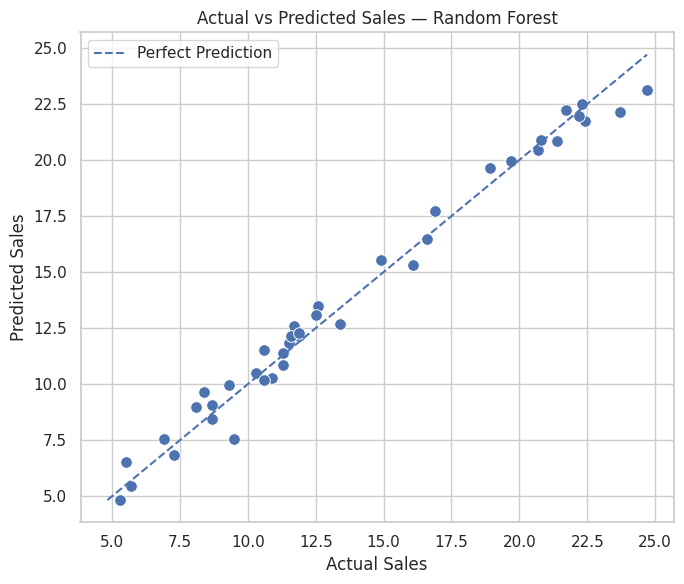

In [13]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=selected_predictions, s=70)

min_value = min(y_test.min(), selected_predictions.min())
max_value = max(y_test.max(), selected_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--", label="Perfect Prediction")

plt.title(f"Actual vs Predicted Sales — {selected_model_name}")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Residual Analysis

Residuals are calculated as:

`residual = actual_sales - predicted_sales`

A good residual plot often shows points scattered around zero without a strong systematic pattern. Visible curves, funnels, clusters, or extreme points can suggest model limitations. Visual inspection should be treated as evidence, not proof of a specific statistical problem.

Residual statistics:


,Residual
count,40.000000
mean,-0.045908
std,0.748324
min,-1.269667
25%,-0.651000
50%,-0.206000
75%,0.442500
max,1.936000


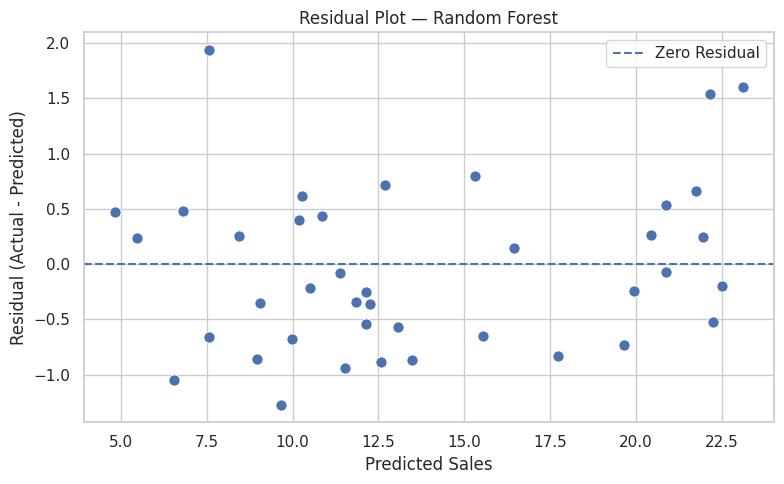

In [14]:
residuals = y_test.to_numpy() - selected_predictions

residual_summary = pd.Series(residuals).describe()
print("Residual statistics:")
display(residual_summary.to_frame("Residual"))

plt.figure(figsize=(8, 5))
sns.scatterplot(x=selected_predictions, y=residuals, s=65)
plt.axhline(0, linestyle="--", label="Zero Residual")
plt.title(f"Residual Plot — {selected_model_name}")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Feature Importance / Advertising Impact

There are three different concepts to keep separate:

1. **Linear Regression coefficient:** the model's estimated change in predicted Sales per one-unit feature increase, holding the other included predictors constant.
2. **Random Forest feature importance:** a relative measure of how useful each feature was for reducing impurity across the forest's trees. It is not a causal effect and does not have the same units as a regression coefficient.
3. **Correlation:** a pairwise measure of linear association between two variables; it does not control for the other predictors and does not establish causation.

For the project's question about the channel with the highest *impact*, the safest wording is the channel with the strongest **predictive contribution/association in this model**, not a proven causal impact.

Linear Regression coefficients:


,Feature,Coefficient,Absolute Coefficient
1,Radio Ad Budget ($),0.189195,0.189195
0,TV Ad Budget ($),0.044730,0.044730
2,Newspaper Ad Budget ($),0.002761,0.002761


Random Forest feature importance:


,Feature,Random Forest Importance
0,TV Ad Budget ($),0.625447
1,Radio Ad Budget ($),0.361745
2,Newspaper Ad Budget ($),0.012808


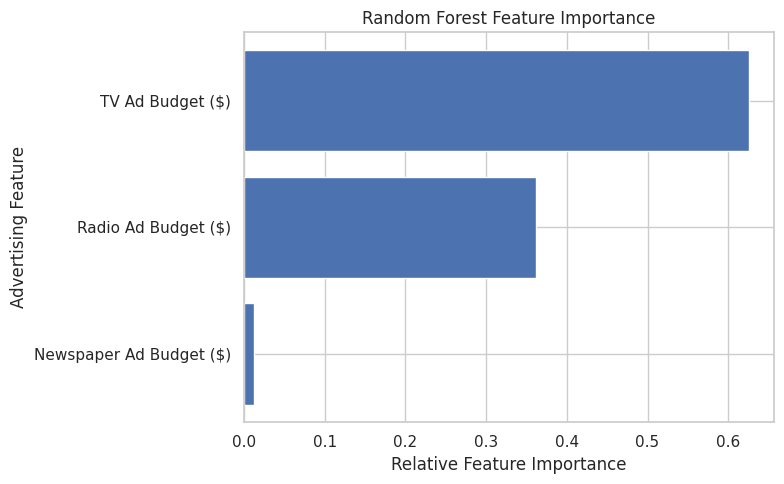

Highest Random Forest predictive importance: TV Ad Budget ($)
Strongest absolute Pearson correlation with Sales: TV Ad Budget ($)
Largest absolute Linear Regression coefficient: Radio Ad Budget ($)


In [15]:
# Linear Regression coefficients
linear_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_,
    "Absolute Coefficient": np.abs(linear_model.coef_)
}).sort_values("Absolute Coefficient", ascending=False)

print("Linear Regression coefficients:")
display(linear_importance)

# Random Forest feature importance
rf_importance = pd.DataFrame({
    "Feature": X.columns,
    "Random Forest Importance": random_forest.feature_importances_
}).sort_values("Random Forest Importance", ascending=False)

print("Random Forest feature importance:")
display(rf_importance)

plt.figure(figsize=(8, 5))
plt.barh(rf_importance["Feature"], rf_importance["Random Forest Importance"])
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Relative Feature Importance")
plt.ylabel("Advertising Feature")
plt.tight_layout()
plt.show()

top_rf_feature = rf_importance.iloc[0]["Feature"]
top_corr_feature = sales_correlations.index[0]
top_lr_feature = linear_importance.iloc[0]["Feature"]

print(f"Highest Random Forest predictive importance: {top_rf_feature}")
print(f"Strongest absolute Pearson correlation with Sales: {top_corr_feature}")
print(f"Largest absolute Linear Regression coefficient: {top_lr_feature}")


## 14. Model Comparison

The table below gives the final test-set comparison. Lower MAE/RMSE and higher R² indicate better predictive performance for these metrics, but the conclusion is specific to this test split and should not be treated as a universal ranking of the algorithms.

In [16]:
comparison = evaluation_results.copy()
display(comparison.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R²": "{:.4f}"
}))

best_rmse_row = comparison.loc[comparison["RMSE"].idxmin()]
print(
    f"On this test split, {best_rmse_row['Model']} has the lower RMSE "
    f"({best_rmse_row['RMSE']:.4f})."
)


,Model,MAE,RMSE,R²
0,Linear Regression,1.4608,1.7816,0.8994
1,Random Forest,0.6131,0.7403,0.9826


On this test split, Random Forest has the lower RMSE (0.7403).


## 15. Final Conclusion

For this uploaded dataset, the notebook computes the exact EDA results, model coefficients, feature importances, test metrics, and residual statistics above.

### Key findings from the uploaded data
- The dataset contains **200 observations and 5 columns** before cleaning.
- `Unnamed: 0` is an index-like identifier and is excluded from modeling.
- The modeling variables are **TV Ad Budget ($), Radio Ad Budget ($), Newspaper Ad Budget ($)** and **Sales ($)**.
- There are **no missing values and no duplicate rows** in the uploaded data.
- The strongest simple linear correlation with Sales is expected to be the TV advertising variable in this dataset, while the final feature-importance values are reported directly by the executed cells.
- Both models are evaluated using MAE, RMSE, and R² rather than R² alone.
- The model used for the detailed Actual-vs-Predicted and residual plots is selected using the lowest observed test RMSE.
- The feature identified as most important is a **predictive association**, not proof that increasing that channel causes Sales to increase.

### Limitations
- The dataset has only 200 observations.
- Results depend on the particular train/test split.
- A single split can give a different result from another split.
- Correlation and model feature importance do not establish causation.
- Random Forest feature importance can be affected by feature relationships and should not be interpreted as a causal effect.
- Cross-validation and additional diagnostics would improve confidence in model comparison.

### Possible improvements
Use k-fold cross-validation, compare additional models, tune hyperparameters using only training data, examine transformed/nonlinear relationships, and evaluate the final approach on a genuinely unseen future or holdout dataset where available.


# 16. Viva / Interview Questions

### 1. What is the target variable?
**Sales** is the target because it is the value the models are trained to predict.

### 2. Why was `Unnamed: 0` removed?
It is an index-like row identifier, not a meaningful advertising predictor. Keeping it could add irrelevant information to the model.

### 3. What is Linear Regression?
It models the target as a linear combination of the input features plus an intercept.

### 4. What does a Linear Regression coefficient mean?
It represents the change in predicted Sales for a one-unit change in that feature while the other included predictors are held constant.

### 5. What is Random Forest Regression?
It is an ensemble method that builds many decision trees and combines their predictions, allowing it to model nonlinear relationships and interactions.

### 6. What is MAE?
Mean Absolute Error is the average absolute difference between actual and predicted values. Lower MAE means smaller average errors.

### 7. What is RMSE?
Root Mean Squared Error is the square root of the average squared prediction error. Because errors are squared first, larger errors receive more weight.

### 8. What is R²?
R² measures the proportion of variation in the target explained by the model on the evaluated data. A value closer to 1 generally indicates stronger explanatory performance.

### 9. Why do we split the data into training and testing sets?
The training set is used to learn the model, while the test set provides an evaluation on observations that were not used for fitting.

### 10. What are residuals?
Residuals are `actual - predicted`. They show the model's prediction errors for individual observations.

### 11. What does a good residual plot look like?
Ideally, residuals are scattered around zero without a strong systematic pattern. Patterns can indicate that the model is missing structure in the data.

### 12. What is correlation?
Correlation measures the strength and direction of association between two variables. It does not prove causation.

### 13. What is Random Forest feature importance?
It is a relative measure of how much each feature contributes to reducing impurity across the trees. It is not a causal effect and is not directly comparable in units to a regression coefficient.

### 14. What is overfitting?
Overfitting happens when a model learns the training data too closely, including noise, and performs substantially worse on unseen data.

### 15. Why might Random Forest outperform Linear Regression?
If the relationship between advertising spend and Sales contains nonlinear patterns or interactions, Random Forest can model them while ordinary Linear Regression assumes a linear functional form.


# 17. Project Summary for Report / GitHub README

Built a **Sales Prediction using Python** machine learning project using an uploaded advertising dataset containing TV, Radio, Newspaper, and Sales variables. The project performs data inspection, cleaning, exploratory data analysis, correlation analysis, train/test splitting, Linear Regression and Random Forest Regression, and evaluation using MAE, RMSE, and R². It also includes Actual-vs-Predicted and residual visualizations plus model-based feature-importance analysis. The analysis identifies which advertising channel has the strongest predictive association with Sales while explicitly distinguishing predictive relationships from causal impact. The project is implemented in a clean, reproducible Jupyter Notebook using pandas, NumPy, scikit-learn, matplotlib, and seaborn.
